# Characterising an exomoon with Pandora on the GPU

This notebook repeats the full fit of `tutorial_characterisation.ipynb` (same system, same simulated light curve,
same detrending, likelihood and priors), with one change:

```python
sampler = pandora.NestedSampler(like, priors, device="gpu")
```

Everything else (the results, `print_results()`, the posterior samples, `parameters()`) works as on the CPU. Read the
CPU tutorial first for the explanations of each step; here we focus on what changes on the GPU, the run time, and
how the two devices compare.

**Installation:** `pip install pandoramoon[gpu]` (NVIDIA GPU with a recent driver; the CUDA Python packages
`cuda-core`, `cuda-bindings`, `nvidia-cuda-nvrtc` and `numba-cuda` are installed with it, no CUDA toolkit needed).

In [1]:
%matplotlib inline
import time as timer
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [12, 4]

import pandoramoon as pandora
from pandoramoon.search import model_flux, cadence_times
from pandoramoon import gpu

print("GPU backend available:", gpu.available())
from numba import cuda
dev = cuda.get_current_device()
print(f"GPU: {dev.name.decode() if isinstance(dev.name, bytes) else dev.name}, compute capability "
      f"{dev.compute_capability}, {dev.MULTIPROCESSOR_COUNT} multiprocessors")
import os
print("CPU threads:", os.cpu_count())

GPU backend available: True
GPU: NVIDIA GeForce RTX 5060, compute capability ComputeCapability(major=12, minor=0), 30 multiprocessors
CPU threads: 32


## The hardware

This notebook ran on a desktop computer with

- an **NVIDIA GeForce RTX 5060** (8 GB): a current consumer graphics card (Blackwell generation, 30 multiprocessors
  with 128 FP32 cores each, 3840 in total). Like all consumer cards it is fast in single precision (FP32) and slow in
  double precision (FP64 at 1/64 of the FP32 rate). Pandora's GPU model is therefore written in FP32 throughout:
  every step (orbits, sky positions, occultation, mutual eclipses, the chi^2) was re-derived for FP32 and validated
  against the FP64 CPU model (log-likelihood errors of a few 10^-4 nats near the posterior, far below the
  sampler's own noise). Only a few reference offsets (times, phases) are kept in FP64.
- an **AMD Ryzen 9 7950X** (16 cores, 32 threads), the computer of the CPU tutorial's run time. The CPU fit below
  uses all of its threads.

How the sampler uses the GPU: it runs ~66 independent nested-sampling runs at once, each with 62 parallel chains,
so ~4000 likelihood evaluations are in flight at any time (one GPU warp of 32 threads per evaluation, the cadences of
a light curve spread over its threads). The planet-only model is fitted on the CPU at the same time (importance
sampling, seconds); only the planet+moon model, which takes almost all of the time, runs on the GPU. The fit's
checks, escalations and results are the same code as on the CPU.

## 1. The system and the light curve

Identical to the CPU tutorial (sections 1-2).

In [2]:
R_sun = 696_342_000  # [m]

def make_system(with_moon=True):
    params = pandora.model_params()
    # the star: like the Sun, with quadratic limb darkening u1, u2
    params.R_star = R_sun        # [m]
    params.u1 = 0.4089
    params.u2 = 0.2556
    # the planet: a Jupiter on a one-year orbit
    params.per_bary = 365.25     # orbital period of the planet-moon barycentre [days]
    params.a_bary = 215          # semi-major axis [stellar radii]; 215 R_sun = 1 AU
    params.r_planet = 0.1        # planet radius [stellar radii]; 0.1 R_sun = 1 Jupiter radius
    params.b_bary = 0.3          # impact parameter (0 = central transit)
    params.t0_bary = 11          # time of the first transit [days]
    params.t0_bary_offset = 0.01 # small shift of that time [days]
    params.M_planet = 1.8986e27  # [kg], 1 Jupiter mass
    params.w_bary = 0            # circular orbit
    params.ecc_bary = 0
    # the moon: about 3 Earth radii, 5-day orbit, 5 % of the planet's mass
    params.r_moon = 0.03 if with_moon else 1e-6    # [stellar radii]
    params.per_moon = 5          # [days]
    params.tau_moon = 0.07       # orbital phase of the moon at the first transit [0..1]
    params.Omega_moon = 0        # orientation of the moon's orbit [deg]
    params.i_moon = 90           # inclination of the moon's orbit [deg]; 90 = seen edge-on
    params.ecc_moon = 0
    params.w_moon = 0
    params.M_moon = (0.054 if with_moon else 1e-9) * params.M_planet   # [kg]
    # observing: 3 transits, 10 days of 30-min data around each
    params.epochs = 3
    params.epoch_duration = 10   # [days]
    params.cadences_per_day = 48 # 30-min cadence
    params.epoch_distance = 365.25
    params.occult_small_threshold = 0   # exact planet-moon overlaps
    params.hill_sphere_threshold = 1.0  # moons beyond the Hill sphere are not allowed
    return params

In [3]:
def simulate_lightcurve(params, seed=1, white_noise=400e-6, red_noise=120e-6, artefact=None):
    """Simulated 30-min light curve of `params` (a pandora.model_params) with exposure smearing,
    stellar variability, white and red noise. artefact = (epoch, offset [d], depth, duration [d]):
    an extra box-shaped dip in one transit (to imitate an instrumental glitch)."""
    rng = np.random.default_rng(seed)
    # (1) the time stamps of the data points (one every 30 min), and the true flux averaged over each exposure
    params.supersampling_factor = 1
    time = pandora.time(params).grid()
    params.supersampling_factor = 30                     # 30 sub-exposures per data point
    flux_true, _, _ = pandora.moon_model(params).light_curve(pandora.time(params).grid())
    # (2) stellar variability: two slow waves (star spots)
    star = 1 + 400e-6 * np.sin(2 * np.pi * time / 6.3 + 1.0) + 600e-6 * np.sin(2 * np.pi * time / 13.7 + 2.0)
    # (3) red noise: random wiggles correlated over ~6 data points (3 hours) ...
    a = np.exp(-1 / 6.0)
    kick = rng.normal(0, 1, len(time))
    red = np.zeros(len(time))
    for i in range(1, len(time)):
        red[i] = a * red[i - 1] + np.sqrt(1 - a * a) * kick[i]
    # ... and white noise
    flux = flux_true * (star + red_noise * red) + rng.normal(0, white_noise, len(time))
    if artefact is not None:
        epoch, offset, depth, duration = artefact
        tc = params.t0_bary + params.t0_bary_offset + epoch * params.per_bary + offset
        box = 0.25 * (1 + np.tanh((time - tc + duration / 2) / 0.02)) * (1 - np.tanh((time - tc - duration / 2) / 0.02))
        flux = flux - depth * box
    return time, flux

In [4]:
params = make_system(with_moon=True)
time, flux = simulate_lightcurve(params, seed=1)

# the moon's own contribution, without noise (for the plots below)
params.supersampling_factor = 30
_, flux_planet_true, flux_moon_true = pandora.moon_model(params).light_curve(pandora.time(params).grid())
params.supersampling_factor = 1

Pandora: compiling numerical code (first use after installation or an update can take a few minutes; the result is cached) ...


## 2. Detrending, likelihood and priors

Identical to the CPU tutorial (sections 3-4): `prepare_lightcurve` with the default mask (1.0 x T14) and window
(4.0 x T14), errors sigma x beta, Pandora's default priors.

T14 = 13.7 h; sigma = 413 ppm, beta = 1.18; 249 points in the fit windows


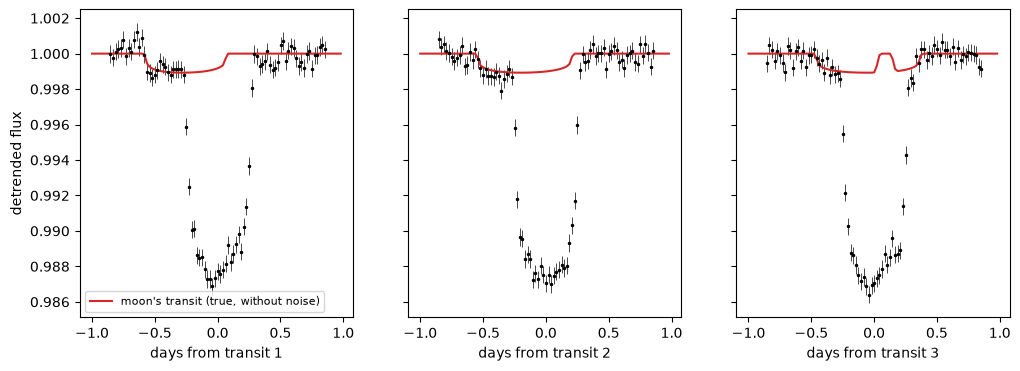

In [5]:
T14 = params.per_bary / np.pi * np.arcsin(np.sqrt((1 + params.r_planet) ** 2 - params.b_bary ** 2) / params.a_bary)
t0 = params.t0_bary + params.t0_bary_offset
lc = pandora.prepare_lightcurve(time, flux, t0=t0, period=params.per_bary, duration=T14)
print(f"T14 = {24 * T14:.1f} h; sigma = {1e6 * lc['sigma']:.0f} ppm, beta = {lc['beta']:.2f}; "
      f"{len(lc['time'])} points in the fit windows")

fig, axs = plt.subplots(1, 3, sharey=True)
for k, ax in enumerate(axs):
    tc = t0 + k * params.per_bary
    m = np.abs(lc["time"] - tc) < 1
    ax.errorbar(lc["time"][m] - tc, lc["flux"][m], lc["flux_err"][m], fmt=".", color="k", ms=3, elinewidth=0.5)
    mt = np.abs(time - tc) < 1
    ax.plot(time[mt] - tc, flux_moon_true[mt], color="C3", label="moon's transit (true, without noise)")
    ax.set_xlabel(f"days from transit {k + 1}")
axs[0].set_ylabel("detrended flux"); axs[0].legend(fontsize=8)
plt.show()

In [6]:
like = pandora.Likelihood(lc["time"], lc["flux"], lc["flux_err"], epoch_distance=params.per_bary,
                          hill_sphere_threshold=1.0)
priors = pandora.default_priors(t0_bary=params.t0_bary, per_bary=params.per_bary, r_planet=0.1)
for name, prior in priors.items():
    print(f"{name:16s} {prior}")

q1               Uniform(lo=0.0, hi=1.0)
q2               Uniform(lo=0.0, hi=1.0)
R_star           Uniform(lo=557073600.0, hi=835610400.0)
per_bary         Uniform(lo=364.5195, hi=365.9805)
a_bary           LogUniform(lo=85.95973586976356, hi=537.2483491860223)
r_planet         Uniform(lo=0.05, hi=0.15000000000000002)
b_bary           Uniform(lo=0.0, hi=1.0)
t0_bary          11.0
t0_bary_offset   Uniform(lo=-0.05, hi=0.05)
M_planet         Uniform(lo=9.49065e+26, hi=2.847195e+27)
r_moon           Uniform(lo=0.010000000000000002, hi=0.06999999999999999)
per_moon         Uniform(lo=0.0, hi=69.397)
tau_moon         Uniform(lo=0.0, hi=1.0)
Omega_moon       Uniform(lo=0.0, hi=180.0)
i_moon           Uniform(lo=0.0, hi=180.0)
M_moon           Uniform(lo=0.0, hi=9.49065e+26)


## 3. The full fit on the GPU

`device="gpu"` is the only change. `supersampling="auto"` (the default) again computes each 30-min data point from
5 sub-exposures. The first call compiles the GPU kernels (a few seconds, cached afterwards).

In [7]:
sampler = pandora.NestedSampler(like, priors, device="gpu", log_dir="results_characterisation_gpu",
                                resume="overwrite", verbose=False)
t_start = timer.time()
results = sampler.run()            # accuracy="medium" (default)
t_gpu = timer.time() - t_start
print(f"run time: {t_gpu / 60:.1f} min (planet+moon fit {results['wall']:.0f} s, planet-only fit "
      f"{results['planet']['wall']:.0f} s, concurrently on the CPU)")

run time: 0.8 min (planet+moon fit 36 s, planet-only fit 17 s, concurrently on the CPU)


In [8]:
sampler.print_results()

planet + moon: logZ = -138.885 +- 0.117   (checks passed; 33 runs x 500 live, nsteps 64, 493,824,596 calls, 36 s)
    q1              : 0.381479 -0.155 +0.209   (mean 0.40742, sd 0.181)
    q2              : 0.282532 -0.128 +0.203   (mean 0.318743, sd 0.178)
    R_star          : 6.94728e+08 -8.07e+07 +7.76e+07   (mean 6.93958e+08, sd 7.05e+07)
    per_bary        : 365.257 -0.00578 +0.00679   (mean 365.258, sd 0.00598)
    a_bary          : 213.562 -8.2 +7.33   (mean 213.059, sd 7.68)
    r_planet        : 0.0996234 -0.00123 +0.00161   (mean 0.0997817, sd 0.00143)
    b_bary          : 0.208198 -0.143 +0.157   (mean 0.215559, sd 0.132)
    t0_bary_offset  : -0.00610822 -0.0169 +0.0143   (mean -0.0074591, sd 0.0148)
    M_planet        : 2.18861e+27 -6.03e+26 +4.56e+26   (mean 2.12686e+27, sd 4.74e+26)
    r_moon          : 0.0312009 -0.00124 +0.00122   (mean 0.0311926, sd 0.00124)
    per_moon        : 5.53006 -0.663 +1.11   (mean 5.78601, sd 1.21)
    tau_moon        : 0.531663 -0.34

In [9]:
print(f"ln Z(planet + moon) = {results['logz']:.2f} +- {results['logzerr']:.2f}")
print(f"ln Z(planet only)   = {results['planet']['logz']:.2f} +- {results['planet']['logzerr']:.2f}")
print(f"Delta ln Z          = {results['dlogz']:.2f} +- {results['dlogzerr']:.2f}")
print("checks passed:", results["passed"], "| notes:", results["warnings"])

ln Z(planet + moon) = -138.88 +- 0.12
ln Z(planet only)   = -215.09 +- 0.02
Delta ln Z          = 76.21 +- 0.12
checks passed: True | notes: ["supersampling: 5 sub-exposures per cadence (cadence 30.0 min; supersampling='auto')"]


## 4. The posterior

As in the CPU tutorial (section 5).

In [10]:
names = results["paramnames"]
S = {n: results["samples"][:, i] for i, n in enumerate(names)}
S["M_moon/M_planet"] = S["M_moon"] / S["M_planet"]
# Omega is reported on 0...180 deg (Omega and Omega + 180 deg give the same light curves at the transits). The true
# value, 0 deg, lies at the edge of that range, so for display we shift it to -90...+90 deg
S["Omega_moon"] = (S["Omega_moon"] + 90) % 180 - 90
truth = dict(r_moon=params.r_moon, per_moon=params.per_moon, i_moon=params.i_moon, Omega_moon=params.Omega_moon,
             **{"M_moon/M_planet": params.M_moon / params.M_planet}, r_planet=params.r_planet, b_bary=params.b_bary)
for n, true in truth.items():
    lo, med, hi = np.percentile(S[n], [15.87, 50, 84.13])
    print(f"{n:16s} {med:.4g}  (68 %: {lo:.4g} ... {hi:.4g})   true: {true:.4g}")

r_moon           0.0312  (68 %: 0.02996 ... 0.03242)   true: 0.03
per_moon         5.53  (68 %: 4.867 ... 6.635)   true: 5
i_moon           90.69  (68 %: 88.24 ... 92.62)   true: 90
Omega_moon       2.733  (68 %: -17.18 ... 14.42)   true: 0
M_moon/M_planet  0.1281  (68 %: 0.05123 ... 0.2317)   true: 0.054
r_planet         0.09962  (68 %: 0.09839 ... 0.1012)   true: 0.1
b_bary           0.2082  (68 %: 0.06556 ... 0.3656)   true: 0.3


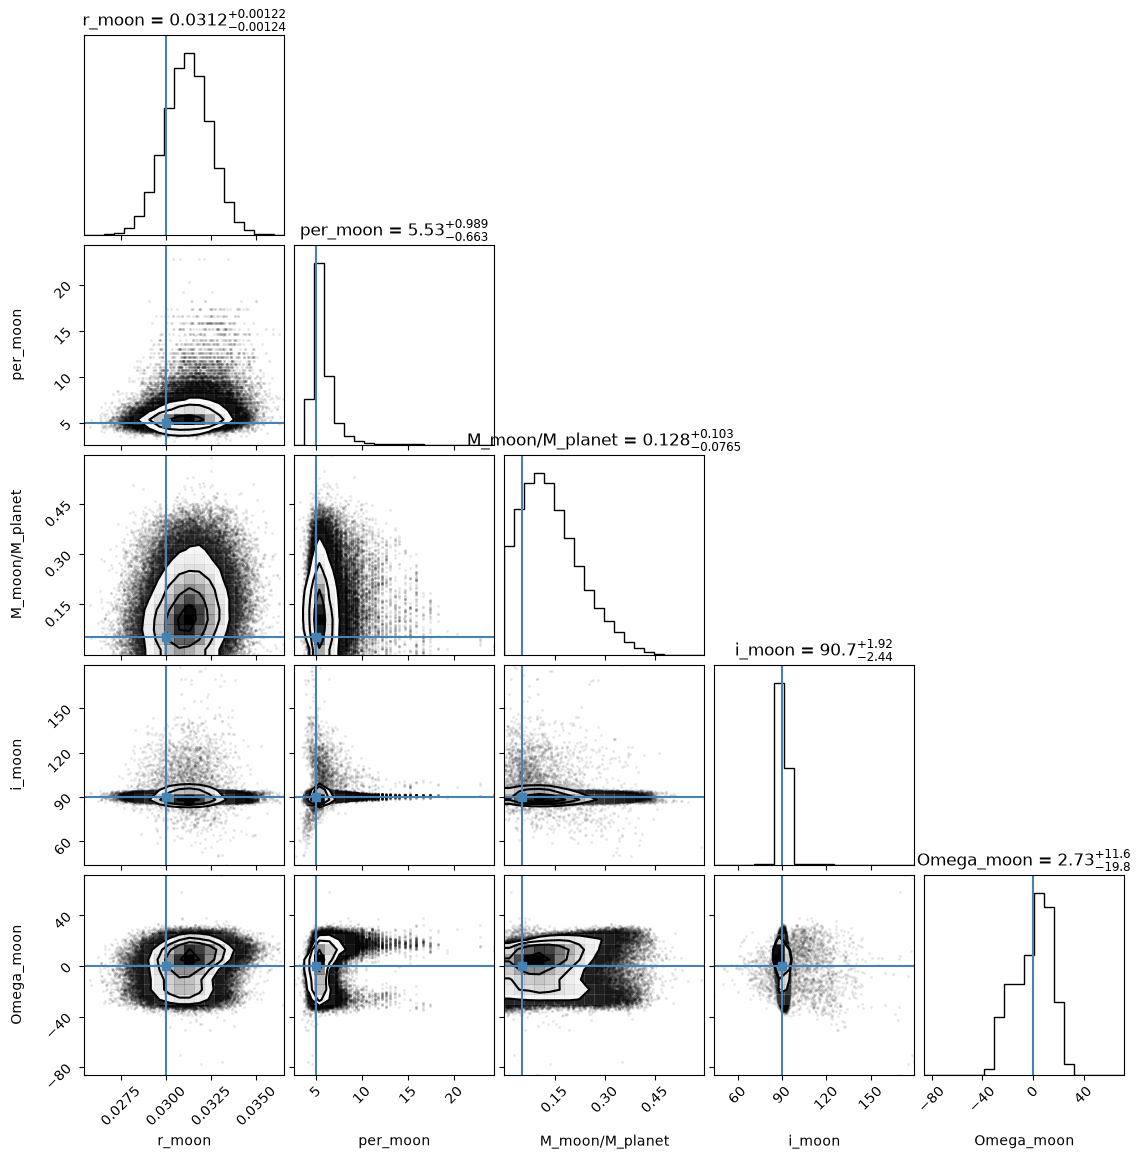

In [11]:
import corner, logging
logging.getLogger().setLevel(logging.ERROR)    # silence corner's note on sparse contour levels
keys = ["r_moon", "per_moon", "M_moon/M_planet", "i_moon", "Omega_moon"]
fig = corner.corner(np.column_stack([S[k] for k in keys]), labels=keys,
                    truths=[truth[k] for k in keys], show_titles=True, title_fmt=".3g")
plt.show()

## 5. The best-fit light curves

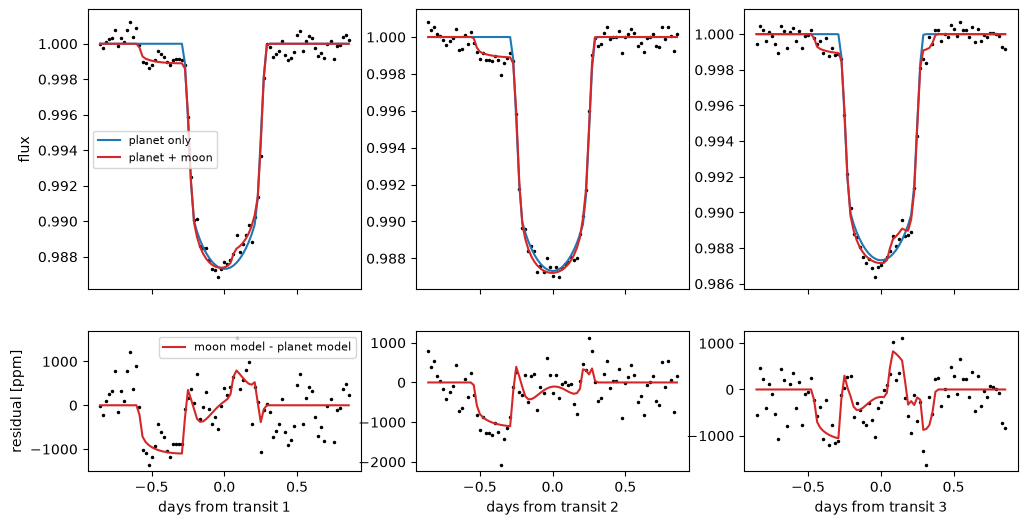

In [12]:
best_moon = sampler.parameters()
best_planet = sampler.parameters(model="planet")
L = sampler.likelihood                         # the likelihood actually used (with 5 sub-exposures)
tc = cadence_times(L)
fm, fp = model_flux(L, best_moon), model_flux(L, best_planet)

fig, axs = plt.subplots(2, 3, sharex="col", figsize=(12, 6), gridspec_kw=dict(height_ratios=[2, 1]))
for k in range(3):
    c0 = t0 + k * params.per_bary
    m = np.abs(tc - c0) < 1
    x = tc[m] - c0
    axs[0, k].plot(x, L.data[m], ".", color="k", ms=3)
    axs[0, k].plot(x, fp[m], color="C0", label="planet only")
    axs[0, k].plot(x, fm[m], color="C3", label="planet + moon")
    axs[1, k].plot(x, 1e6 * (L.data[m] - fp[m]), ".", color="k", ms=3)
    axs[1, k].plot(x, 1e6 * (fm[m] - fp[m]), color="C3", label="moon model - planet model")
    axs[1, k].set_xlabel(f"days from transit {k + 1}")
axs[0, 0].set_ylabel("flux"); axs[1, 0].set_ylabel("residual [ppm]")
axs[0, 0].legend(fontsize=8); axs[1, 0].legend(fontsize=8)
plt.show()

## 6. The same fit on the CPU, for comparison

The same sampler with `device="cpu"` (all 32 threads of the Ryzen 9 7950X), on the same computer and with the same
code. This takes about 3 minutes; skip it if you only want the GPU result. (The run of `tutorial_characterisation.ipynb`
stored in that notebook took 5.9 minutes on the same CPU with the rules of Pandora 2.0, which doubled the chain length
to 128 steps for this light curve; the current rules stop at 64.)

In [13]:
sampler_cpu = pandora.NestedSampler(like, priors, device="cpu", log_dir="results_characterisation_cpu",
                                    resume="overwrite", verbose=False)
t_start = timer.time()
results_cpu = sampler_cpu.run()
t_cpu = timer.time() - t_start

rate = lambda r: r["ncall"] / r["wall"] / 1e6
nruns = lambda r: r["runs"] if isinstance(r["runs"], int) else len(r["runs"])
print(f"{'':28s} {'CPU (32 threads)':>18s} {'GPU (RTX 5060)':>18s}")
print(f"{'ln Z(planet + moon)':28s} {results_cpu['logz']:12.2f} +- {results_cpu['logzerr']:.2f} "
      f"{results['logz']:12.2f} +- {results['logzerr']:.2f}")
print(f"{'Delta ln Z':28s} {results_cpu['dlogz']:18.2f} {results['dlogz']:18.2f}")
print(f"{'nsteps, runs x live points':28s} {results_cpu['nsteps']:8d}, {nruns(results_cpu):3d} x {results_cpu['nlive']}"
      f" {results['nsteps']:8d}, {nruns(results):3d} x {results['nlive']}")
print(f"{'planet+moon fit':28s} {results_cpu['wall']:16.0f} s {results['wall']:16.0f} s")
print(f"{'whole run()':28s} {t_cpu:16.0f} s {t_gpu:16.0f} s")
print(f"{'likelihood calls / s':28s} {rate(results_cpu):14.2f} M {rate(results):16.2f} M")
print(f"\nthe GPU is {results_cpu['wall'] / results['wall']:.1f} x faster on the planet+moon fit, "
      f"{t_cpu / t_gpu:.1f} x on the whole run")

                               CPU (32 threads)     GPU (RTX 5060)
ln Z(planet + moon)               -138.54 +- 0.12      -138.88 +- 0.12
Delta ln Z                                76.55              76.21
nsteps, runs x live points         64,  31 x 500       64,  33 x 500
planet+moon fit                           164 s               36 s
whole run()                               171 s               45 s
likelihood calls / s                   3.11 M            13.72 M

the GPU is 4.5 x faster on the planet+moon fit, 3.8 x on the whole run


**The comparison** (this computer, the same light curve, data, priors and settings):

| | CPU (32 threads) | GPU (RTX 5060) | GPU / CPU |
|---|---|---|---|
| planet+moon fit | 164 s | 36 s | **4.5 x faster** |
| whole `run()` (incl. the planet-only fit, 17 s, on the CPU) | 171 s | 45 s | 3.8 x faster |
| likelihood calls per second | 3.1 M | 13.7 M | 4.4 x |

The two fits agree in the Bayes factor (Δln Z 76.55 and 76.21) and in the posteriors. Their ln Z (−138.54 ± 0.12 and
−138.88 ± 0.12) differ by 0.34 ± 0.17 nats (2σ). This is partly noise and partly a known small effect: on this light
curve the GPU fits at 64 chain steps come out ~0.1–0.15 nats low (six seeds: −138.75 ± 0.04, against −138.645 ± 0.05
from long chains of 512 steps), because each GPU run moves 62 chains in parallel rather than one. It is within the
±0.2 target of `accuracy="medium"`; use `accuracy="high"` when you compare evidences at the 0.1-nat level.

This light curve is small (249 data points, 5 sub-exposures each), so the GPU is only partly busy and each call is
cheap on the CPU too. On real light curves the gain is larger:

## 7. Real Kepler light curves

The simulated light curve above is short: 3 transits with ±1.5 T14 of data each (a few hundred points). Real
light curves have more data per transit and more transits; there the GPU's advantage grows with the work per
likelihood call. Measured on the same computer (likelihood of the planet+moon model at posterior points,
including the prior transform; all 30 CPU threads vs the RTX 5060):

| light curve | samples per call | CPU (30 threads) | GPU | GPU / CPU |
|---|---|---|---|---|
| Kepler-747 b (1647 cadences x 5 sub-exposures) | 8235 | 0.45 M calls/s | 4.96 M calls/s | **11 x** |
| Kepler-108 c (649 x 5) | 3245 | 1.43 M calls/s | 14.2 M calls/s | **9.9 x** |

So on real Kepler light curves the likelihood is about **10 x faster** on the GPU than on all cores of a 16-core
desktop CPU. Full fits of real systems (Pandora's validation, GPU_LOG Round 8) agreed with their stored CPU fits
in ln Z, the Bayes factor and the posteriors, and took 124 s instead of 523 s (Kepler-747 b, window 4, the same
computer) to 733 s instead of 3.0 h (Kepler-747 b, window 6, CPU fit on another computer).

## Good practice on the GPU

- **Scope:** circular planet orbits (`ecc_bary = 0`), moon eccentricity up to 0.9, planet and moon radii within
  0.0005 ... 0.25 stellar radii, sorted time. Anything else raises an error; use `device="cpu"` then.
- **Accuracy:** the FP32 likelihood differs from the CPU's by a few 10^-4 nats near the posterior; this is far below
  the evidence error (±0.2 at `accuracy="medium"`).
- **One fit per GPU** is fastest; the GPU is fully used by one fit. Several fits run one after the other.
- **Reproducible:** the same seed gives the same result on the same GPU.
- `gpu_options` (e.g. `dict(slots=33)`) tunes the run pool; the defaults are the measured optimum.